<table class="m01-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/yy/dviz-course/blob/master/docs/m08-histogram/lab08.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a href="https://yyahn.com/dviz-course/m08-histogram/lab08/"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View on Github</a>
  </td>
  <td>
    <a href="https://raw.githubusercontent.com/yy/dviz-course/master/docs/m08-histogram/lab08.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View raw on Github</a>
  </td>
</table>

# Module 8: Histogram and CDF

A deep dive into Histogram and boxplot.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import altair as alt
import pandas as pd

## The tricky histogram with pre-counted data

Let's revisit the table from the class

| Hours | Frequency |
|-------|-----------|
| 0-1   | 4,300     |
| 1-3   | 6,900     |
| 3-5   | 4,900     |
| 5-10  | 2,000     |
| 10-24 | 2,100     |

You can draw a histogram by just providing bins and counts instead of a list of numbers. So, let's try that.

In [3]:
bins = [0, 1, 3, 5, 10, 24]
data = {0.5: 4300, 2: 6900, 4: 4900, 7: 2000, 15: 2100}

In [4]:
data.keys()

dict_keys([0.5, 2, 4, 7, 15])

**Q: Draw histogram using this data.** Useful query: [Google search: matplotlib histogram pre-counted](https://www.google.com/search?client=safari&rls=en&q=matplotlib+histogram+already+counted&ie=UTF-8&oe=UTF-8#q=matplotlib+histogram+pre-counted)

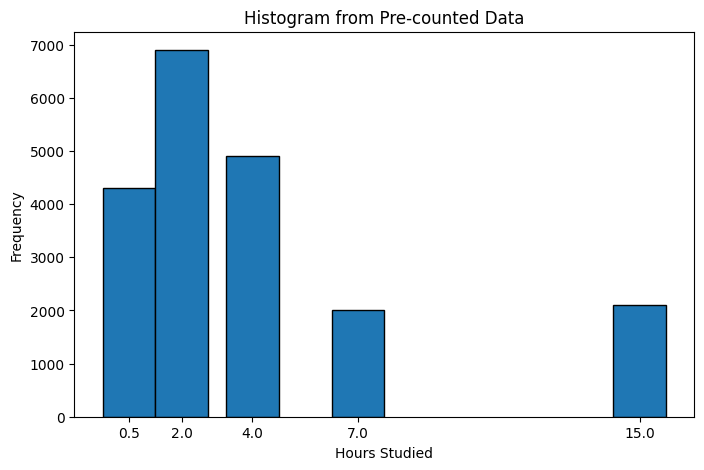

In [5]:
# YOUR SOLUTION HERE

x = list(data.keys())
y = list(data.values())

plt.figure(figsize=(8, 5))
plt.bar(x, y, width=1.5, edgecolor="black")
plt.xticks(x)
plt.xlabel("Hours Studied")
plt.ylabel("Frequency")
plt.title("Histogram from Pre-counted Data")
plt.show()


As you can see, the **default histogram does not normalize with binwidth and simply shows the counts**! This can be very misleading if you are working with variable bin width (e.g. logarithmic bins). So please be mindful about histograms when you work with variable bins.

**Q: You can fix this by using the `density` option.**

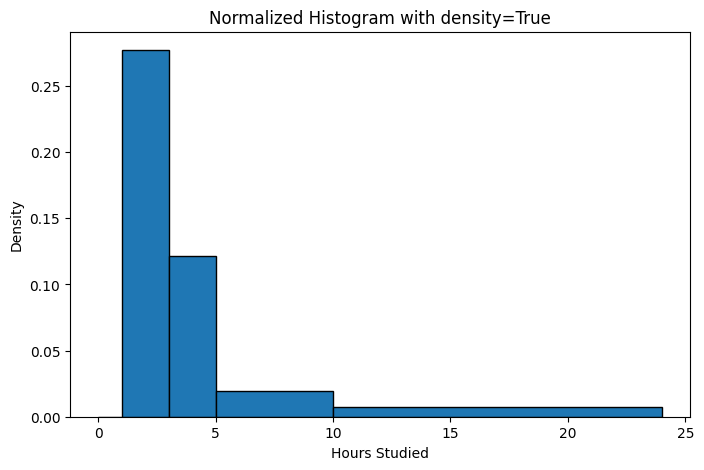

In [6]:
# YOUR SOLUTION HERE

# Recreate the data based on counts
data = {1: 4300, 2: 6900, 4: 4900, 7: 2000, 15: 2100}

# Expand it into a list
samples = []
for k, v in data.items():
    samples.extend([k] * v)

# Draw histogram with density=True
plt.figure(figsize=(8, 5))
plt.hist(samples, bins=[0, 1, 3, 5, 10, 24], density=True, edgecolor='black')
plt.xlabel("Hours Studied")
plt.ylabel("Density")
plt.title("Normalized Histogram with density=True")
plt.show()


## Let's use an actual dataset

In [7]:
import vega_datasets

In [8]:
movies = vega_datasets.data.movies()
movies.head()

,Title,US_Gross,Worldwide_Gross,US_DVD_Sales,Production_Budget,Release_Date,MPAA_Rating,Running_Time_min,Distributor,Source,Major_Genre,Creative_Type,Director,Rotten_Tomatoes_Rating,IMDB_Rating,IMDB_Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,None,None,None,None,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,None,Drama,None,None,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,None,NaN,Lionsgate,None,Comedy,None,None,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,None,NaN,Fine Line,None,Comedy,None,None,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,None,62.0,3.4,165.0


Let's plot the histogram of IMDB ratings.

(array([  9.,  39.,  76., 133., 293., 599., 784., 684., 323.,  48.]),
 array([1.4 , 2.18, 2.96, 3.74, 4.52, 5.3 , 6.08, 6.86, 7.64, 8.42, 9.2 ]),
 <BarContainer object of 10 artists>)

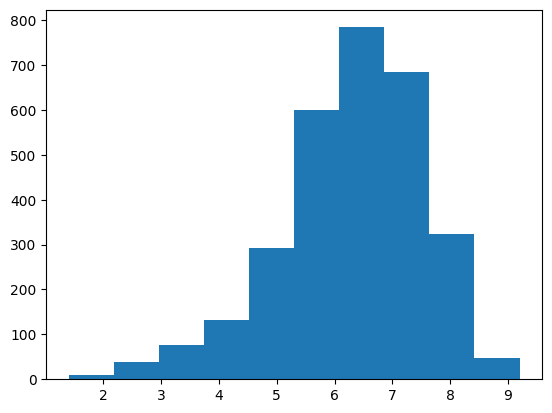

In [9]:
plt.hist(movies.IMDB_Rating)

Did you get an error or a warning? What's going on?

The problem is that the column contains `NaN` (Not a Number) values, which represent missing data points. The following command check whether each value is a `NaN` and returns the result.

In [10]:
movies.IMDB_Rating.isna()

,IMDB_Rating
0,False
1,False
2,False
3,True
4,False
...,...
3196,False
3197,True
3198,False
3199,False


As you can see there are a bunch of missing rows. You can count them.

In [11]:
sum(movies.IMDB_Rating.isna())

213

or drop them.

In [12]:
IMDB_ratings_nan_dropped = movies.IMDB_Rating.dropna()
len(IMDB_ratings_nan_dropped)

2988

In [13]:
213 + 2988

3201

The `dropna` can be applied to the dataframe too.

**Q: drop rows from `movies` dataframe where either `IMDB_Rating` or `IMDB_Votes` is `NaN`.**

In [15]:
# YOUR SOLUTION HERE
movies = movies.dropna(subset=["IMDB_Rating", "IMDB_Votes"])


In [16]:
# Both should be zero.
print(sum(movies.IMDB_Rating.isna()), sum(movies.IMDB_Votes.isna()))

0 0


How does `matplotlib` decides the bins? Actually `matplotlib`'s `hist` function uses `numpy`'s `histogram` function under the hood.

**Q: Plot the histogram of movie ratings (`IMDB_Rating`) using the `plt.hist()` function.**

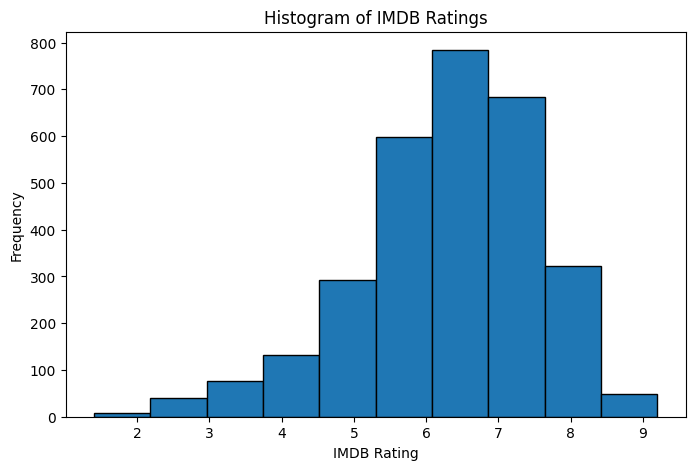

In [17]:
# YOUR SOLUTION HERE
plt.figure(figsize=(8, 5))
plt.hist(movies.IMDB_Rating, bins=10, edgecolor='black')
plt.xlabel("IMDB Rating")
plt.ylabel("Frequency")
plt.title("Histogram of IMDB Ratings")
plt.show()


Have you noticed that this function returns three objects? Take a look at the documentation [here](http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.hist) to figure out what they are.

To get the returned three objects:

[  9.  39.  76. 133. 293. 599. 784. 684. 323.  48.]
[1.4  2.18 2.96 3.74 4.52 5.3  6.08 6.86 7.64 8.42 9.2 ]


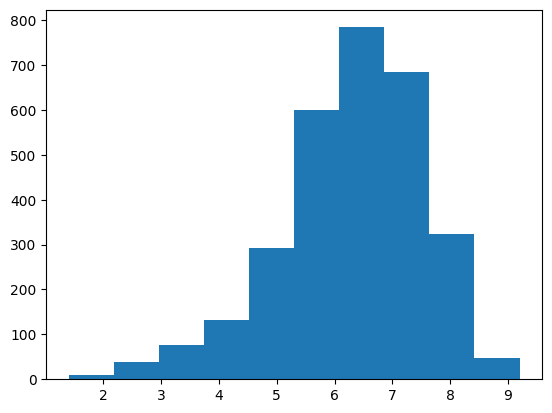

In [18]:
n_raw, bins_raw, patches = plt.hist(movies.IMDB_Rating)
print(n_raw)
print(bins_raw)

Here, `n_raw` contains the values of histograms, i.e., the number of movies in each of the 10 bins. Thus, the sum of the elements in `n_raw` should be equal to the total number of movies.

**Q: Test whether the sum of values in `n_raw` is equal to the number of movies in the `movies` dataset**

In [19]:
# YOUR SOLUTION HERE
sum(n_raw), len(movies), sum(n_raw) == len(movies)


(np.float64(2988.0), 2988, np.True_)

The second returned object (`bins_raw`) is a list containing the edges of the 10 bins: the first bin is \[1.4, 2.18\], the second \[2.18, 2.96\], and so on. What's the width of the bins?

In [20]:
np.diff(bins_raw)

array([0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78])

The width is same as the maximum value minus minimum value, divided by 10.

In [21]:
min_rating = min(movies.IMDB_Rating)
max_rating = max(movies.IMDB_Rating)
print(min_rating, max_rating)
print( (max_rating-min_rating) / 10 )

1.4 9.2
0.7799999999999999


Now, let's plot a normalized (density) histogram.

[0.0038616  0.0167336  0.03260907 0.05706587 0.12571654 0.25701095
 0.33638829 0.29348162 0.13858854 0.0205952 ]
[1.4  2.18 2.96 3.74 4.52 5.3  6.08 6.86 7.64 8.42 9.2 ]


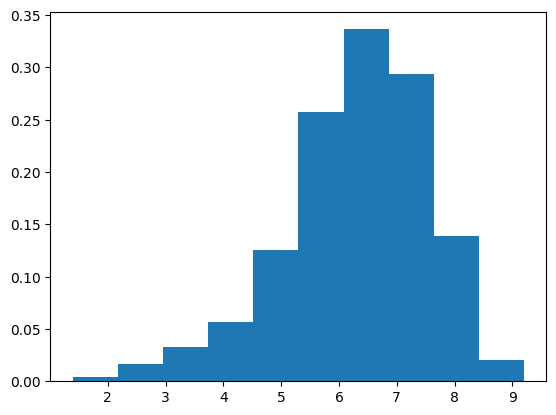

In [22]:
n, bins, patches = plt.hist(movies.IMDB_Rating, density=True)
print(n)
print(bins)

The ten bins do not change. But now `n` represents the density of the data inside each bin. In other words, the sum of the area of each bar will equal to 1.

**Q: Can you verify this?**

Hint: the area of each bar is calculated as height * width. You may get something like 0.99999999999999978 instead of 1.

np.float64(1.0)

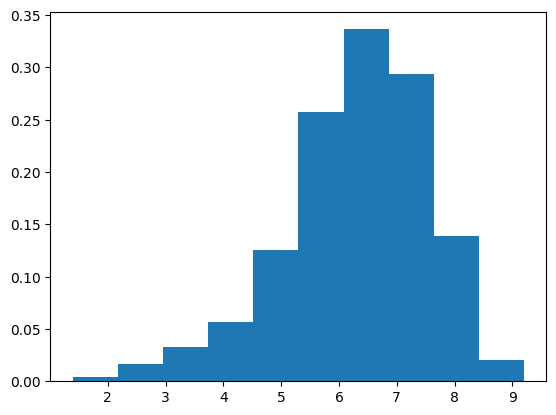

In [23]:
# YOUR SOLUTION HERE

n, bins, patches = plt.hist(movies.IMDB_Rating, bins=10, density=True)
bin_widths = np.diff(bins)
total_area = np.sum(n * bin_widths)
total_area


Anyway, these data generated from the `hist` function is calculated from `numpy`'s `histogram` function. https://docs.scipy.org/doc/numpy/reference/generated/numpy.histogram.html

Note that the result of `np.histogram()` is same as that of `plt.hist()`.

In [24]:
np.histogram(movies.IMDB_Rating)

(array([  9,  39,  76, 133, 293, 599, 784, 684, 323,  48]),
 array([1.4 , 2.18, 2.96, 3.74, 4.52, 5.3 , 6.08, 6.86, 7.64, 8.42, 9.2 ]))

(array([  9.,  39.,  76., 133., 293., 599., 784., 684., 323.,  48.]),
 array([1.4 , 2.18, 2.96, 3.74, 4.52, 5.3 , 6.08, 6.86, 7.64, 8.42, 9.2 ]),
 <BarContainer object of 10 artists>)

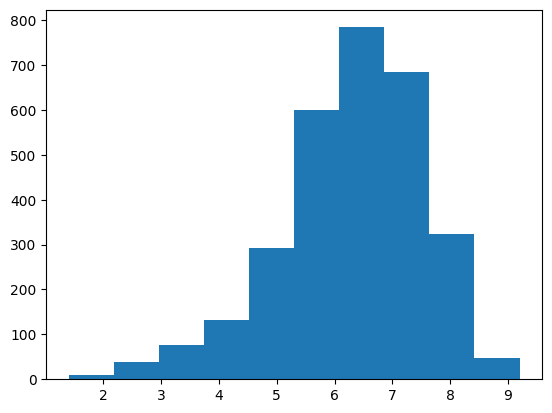

In [25]:
plt.hist(movies.IMDB_Rating)

If you look at the documentation, you can see that `numpy` uses simply 10 as the default number of bins. But you can set it manually or set it to be `auto`, which is the "Maximum of the `sturges` and `fd` estimators.". Let's try this `auto` option.

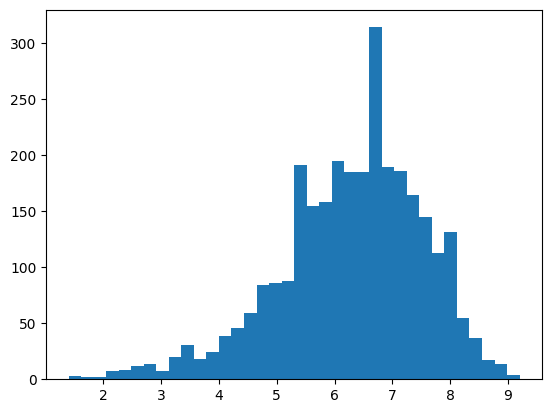

In [26]:
_ = plt.hist(movies.IMDB_Rating, bins='auto')

## Consequences of the binning parameter

Let's explore the effect of bin size using small multiples. In `matplotlib`, you can use [subplot](https://www.google.com/search?client=safari&rls=en&q=matplotlib+subplot&ie=UTF-8&oe=UTF-8) to put multiple plots into a single figure.

For instance, you can do something like:

<Axes: >

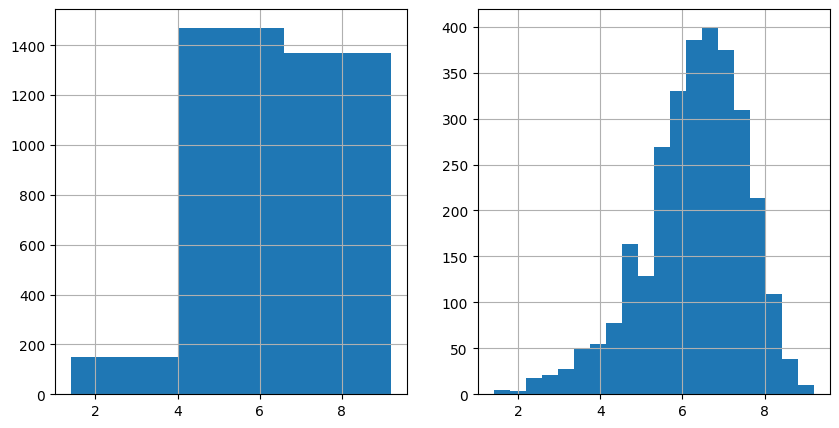

In [27]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
movies.IMDB_Rating.hist(bins=3)
plt.subplot(1,2,2)
movies.IMDB_Rating.hist(bins=20)

What does the argument in `plt.subplot(1,2,1)` mean? If you're not sure, check out: http://stackoverflow.com/questions/3584805/in-matplotlib-what-does-the-argument-mean-in-fig-add-subplot111

**Q: create 8 subplots (2 rows and 4 columns) with the following `binsizes`.**

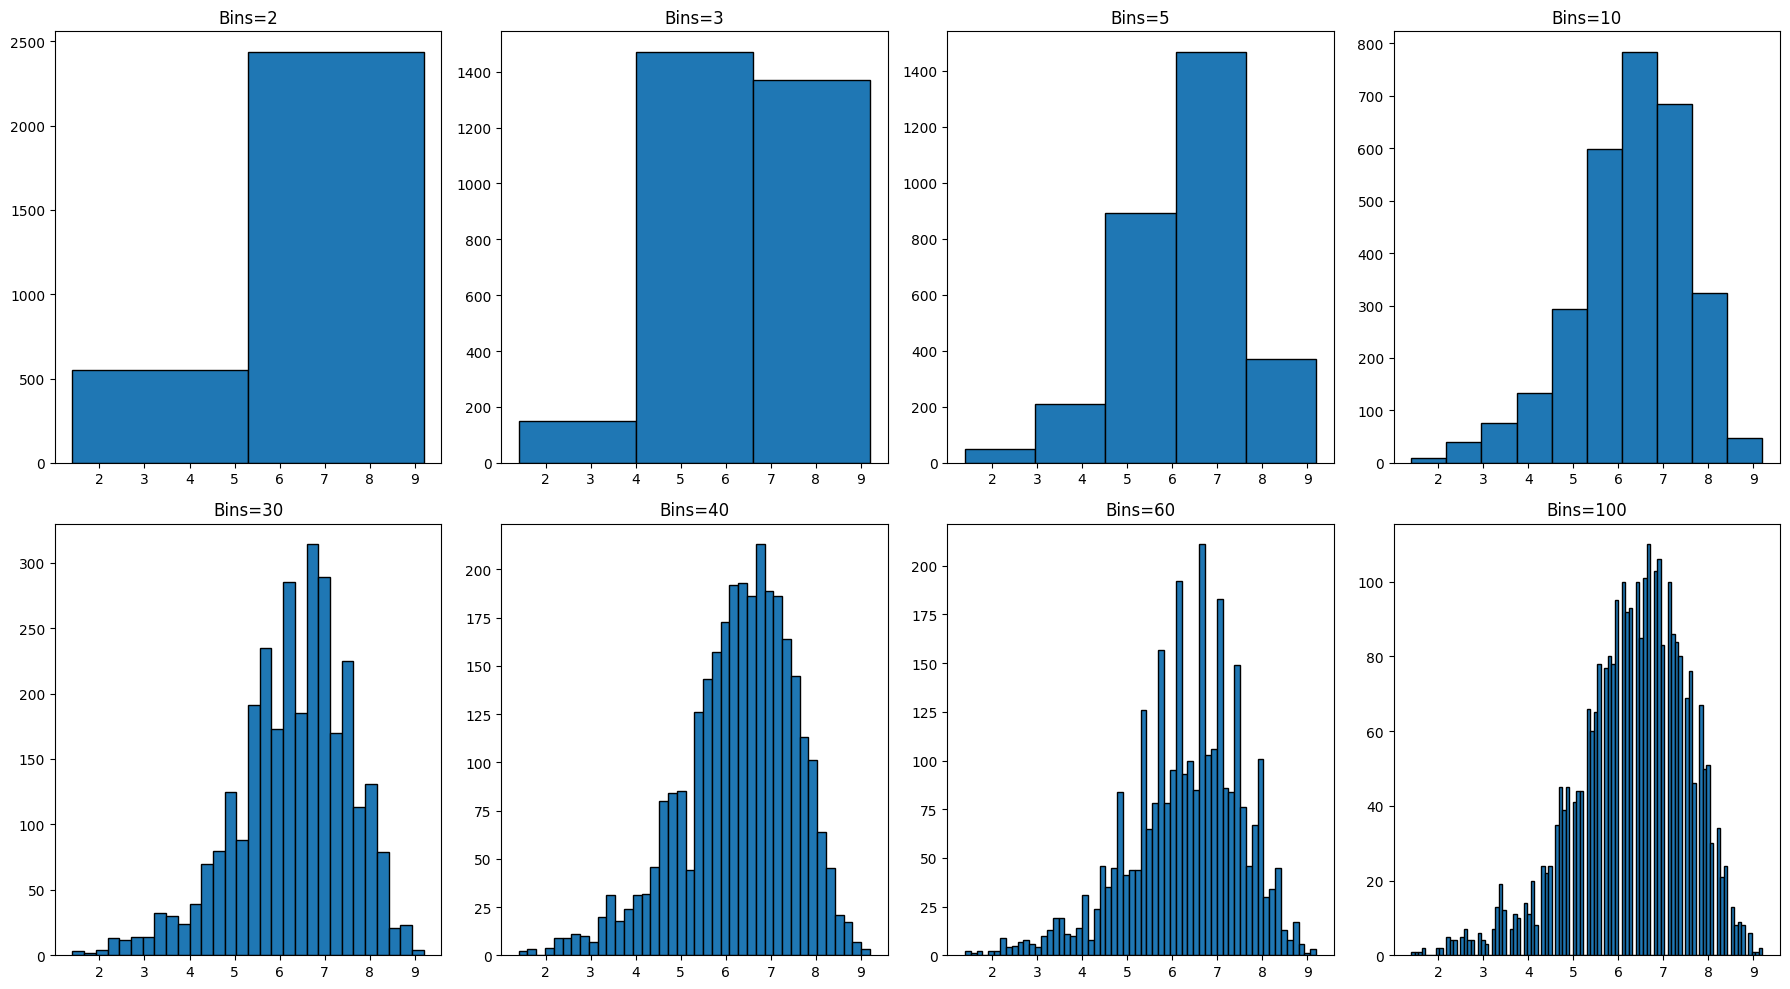

In [28]:
nbins = [2, 3, 5, 10, 30, 40, 60, 100 ]
figsize = (18, 10)

# TODO

# YOUR SOLUTION HERE

fig, axs = plt.subplots(2, 4, figsize=(18, 10))
nbins = [2, 3, 5, 10, 30, 40, 60, 100]

for ax, bins in zip(axs.flatten(), nbins):
    ax.hist(movies.IMDB_Rating, bins=bins, edgecolor='black')
    ax.set_title(f"Bins={bins}")

plt.tight_layout()
plt.show()


Do you see the issues with having too few bins or too many bins? In particular, do you notice weird patterns that emerge from `bins=30`?

**Q: Can you guess why do you see such patterns? What are the peaks and what are the empty bars? What do they tell you about choosing the binsize in histograms?**

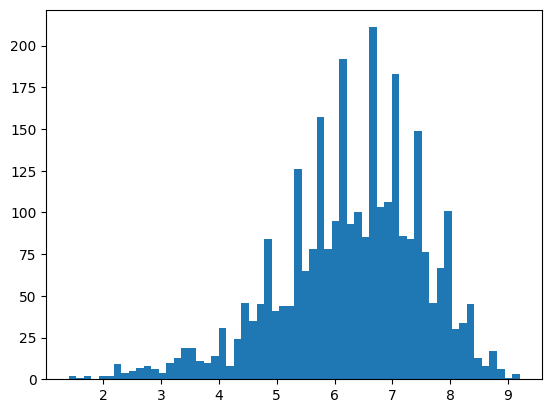

In [ ]:
# YOUR SOLUTION HERE

# When there are too few bins, we lose important details and the histogram looks overly simplified.
# On the other hand, when there are too many bins (like bins=30), the histogram becomes too noisy.
# We start seeing strange peaks and empty bars that may not reflect the true data distribution.
# These peaks can be misleading, and the gaps (empty bars) might occur due to very few data points falling into some bins.
# This shows that bin size should be carefully chosen — not too small to avoid overfitting, and not too large to avoid oversimplification.


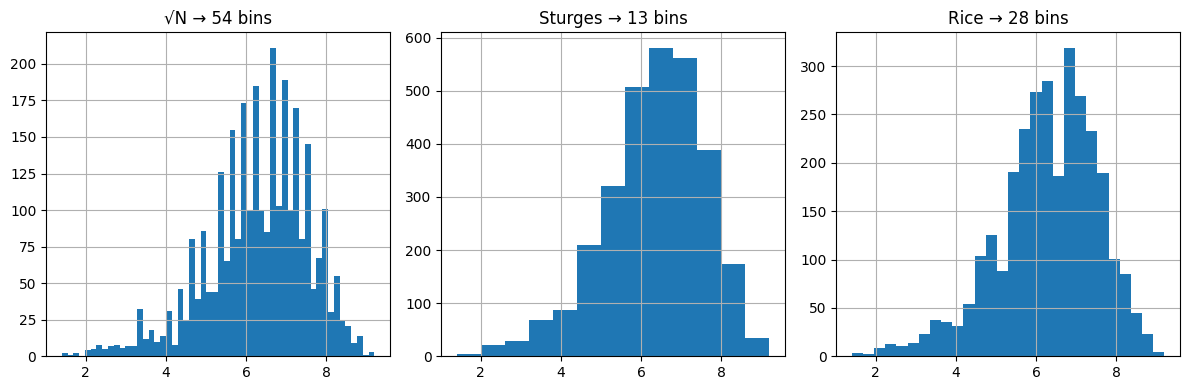

In [29]:
# YOUR SOLUTION HERE
import numpy as np

N = len(movies)

plt.figure(figsize=(12, 4))

# √N rule
nbins = int(np.sqrt(N))
plt.subplot(1, 3, 1)
plt.title("√N → {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)

# Sturges' formula
nbins = int(np.ceil(np.log2(N)) + 1)
plt.subplot(1, 3, 2)
plt.title("Sturges → {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)

# Rice Rule
nbins = int(2 * N ** (1/3))
plt.subplot(1, 3, 3)
plt.title("Rice → {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)

plt.tight_layout()
plt.show()


# YOUR SOLUTION HERE

## Formulae for choosing the number of bins.

We can manually choose the number of bins based on those formulae.

<Axes: title={'center': 'F-D, 35 bins'}>

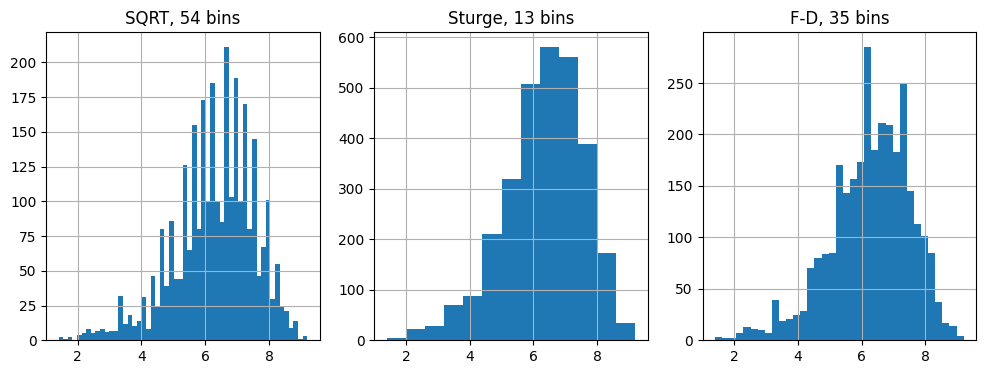

In [30]:
N = len(movies)

plt.figure(figsize=(12,4))

# Sqrt
nbins = int(np.sqrt(N))

plt.subplot(1,3,1)
plt.title("SQRT, {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)

# Sturge's formula
nbins = int(np.ceil(np.log2(N) + 1))

plt.subplot(1,3,2)
plt.title("Sturge, {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)

# Freedman-Diaconis
iqr = np.percentile(movies.IMDB_Rating, 75) - np.percentile(movies.IMDB_Rating, 25)
width = 2*iqr/np.power(N, 1/3)
nbins = int((max(movies.IMDB_Rating) - min(movies.IMDB_Rating)) / width)

plt.subplot(1,3,3)
plt.title("F-D, {} bins".format(nbins))
movies.IMDB_Rating.hist(bins=nbins)



But we can also use built-in formulae too. Let's try all of them.

<Axes: >

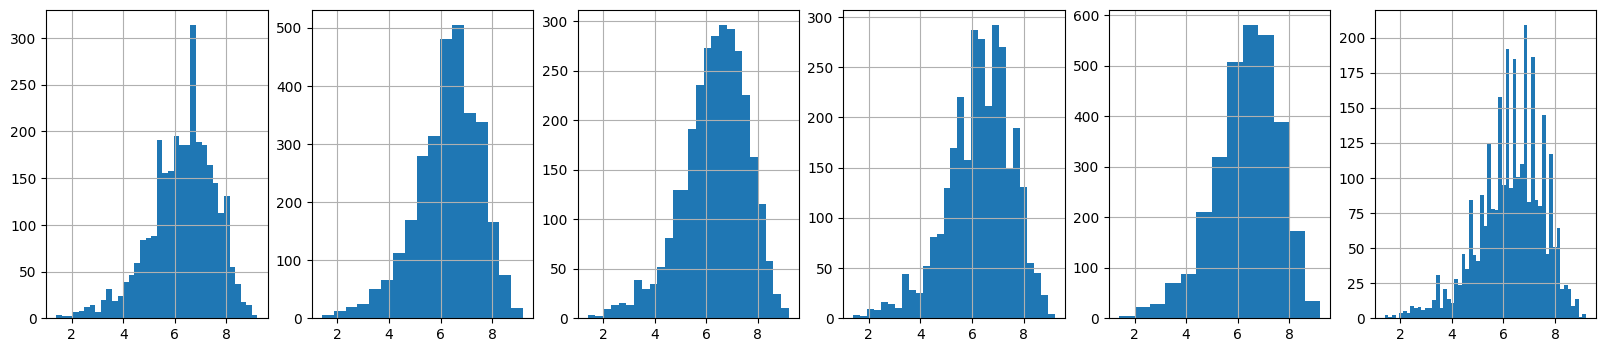

In [31]:
plt.figure(figsize=(20,4))

plt.subplot(161)
movies.IMDB_Rating.hist(bins='fd')

plt.subplot(162)
movies.IMDB_Rating.hist(bins='doane')

plt.subplot(163)
movies.IMDB_Rating.hist(bins='scott')

plt.subplot(164)
movies.IMDB_Rating.hist(bins='rice')

plt.subplot(165)
movies.IMDB_Rating.hist(bins='sturges')

plt.subplot(166)
movies.IMDB_Rating.hist(bins='sqrt')

Some are decent, but several of them tend to overestimate the good number of bins. As you have more data points, some of the formulae may overestimate the necessary number of bins. Particularly in our case, because of the precision issue, we shouldn't increase the number of bins too much.

### Then, how should we choose the number of bins?

So what's the conclusion? use Scott's rule or Sturges' formula?

No, I think the take-away is that you **should understand how the inappropriate number of bins can mislead you** and you should **try multiple number of bins** to obtain the most accurate picture of the data. Although the 'default' may work in most cases, don't blindly trust it! Don't judge the distribution of a dataset based on a single histogram. Try multiple parameters to get the full picture!

## CDF (Cumulative distribution function)

Drawing a CDF is easy. Because it's very common data visualization, histogram has an option called `cumulative`.

<Axes: >

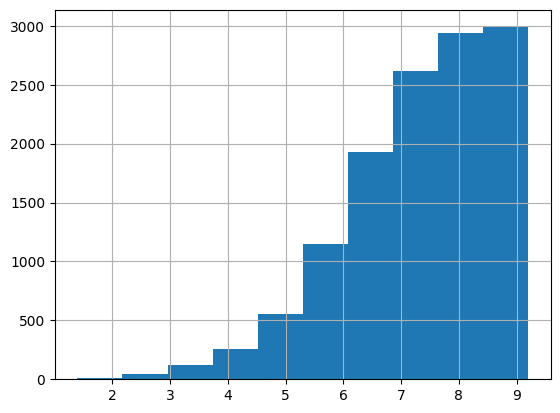

In [32]:
movies.IMDB_Rating.hist(cumulative=True)

You can also combine with options such as `histtype` and `density`.

<Axes: >

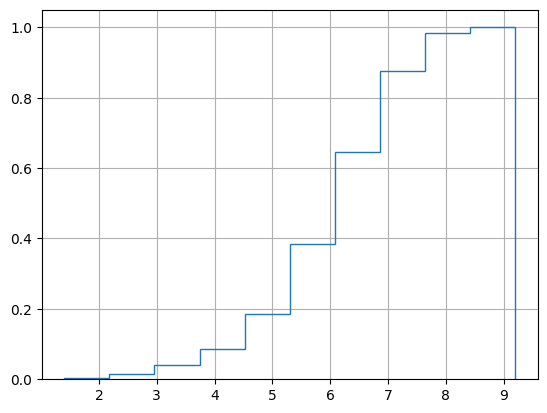

In [33]:
movies.IMDB_Rating.hist(histtype='step', cumulative=True, density=True)

And increase the number of bins.

<Axes: >

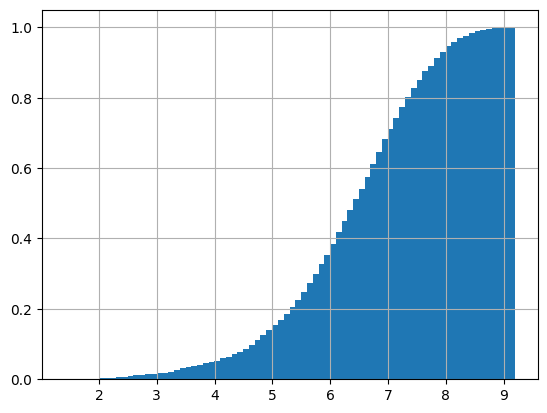

In [34]:
movies.IMDB_Rating.hist(cumulative=True, density=True, bins=1000)

This method works fine. By increasing the number of bins, you can get a CDF in the resolution that you want. But let's also try it manually to better understand what's going on. First, we should sort all the values.

In [35]:
rating_sorted = movies.IMDB_Rating.sort_values()
rating_sorted.head()

,IMDB_Rating
1247,1.4
406,1.5
1754,1.6
1515,1.7
1590,1.7


We need to know the number of data points,

In [36]:
N = len(rating_sorted)
N

2988

And I think this may be useful for you.

In [37]:
n = 50
np.linspace(1/n, 1.0, num=n)

array([0.02, 0.04, 0.06, 0.08, 0.1 , 0.12, 0.14, 0.16, 0.18, 0.2 , 0.22,
       0.24, 0.26, 0.28, 0.3 , 0.32, 0.34, 0.36, 0.38, 0.4 , 0.42, 0.44,
       0.46, 0.48, 0.5 , 0.52, 0.54, 0.56, 0.58, 0.6 , 0.62, 0.64, 0.66,
       0.68, 0.7 , 0.72, 0.74, 0.76, 0.78, 0.8 , 0.82, 0.84, 0.86, 0.88,
       0.9 , 0.92, 0.94, 0.96, 0.98, 1.  ])

**Q: now you're ready to draw a proper CDF. Draw the CDF plot of this data.**

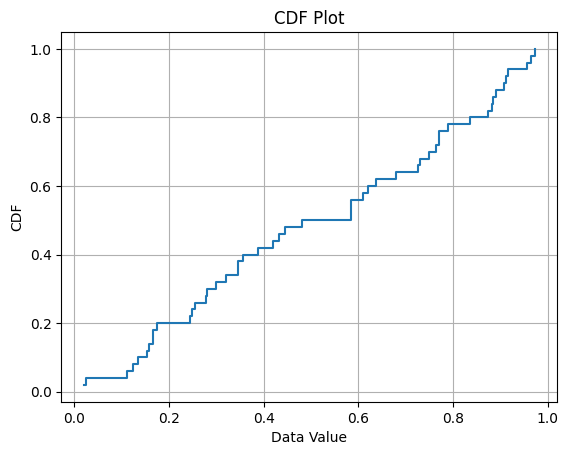

In [38]:
# YOUR SOLUTION HERE

n = 50
x = np.sort(np.random.rand(n))  # Or use your actual sorted data
y = np.linspace(1/n, 1.0, num=n)

plt.plot(x, y, drawstyle='steps-post')
plt.xlabel("Data Value")
plt.ylabel("CDF")
plt.title("CDF Plot")
plt.grid(True)
plt.show()


## A bit more histogram with altair

As you may remember, you can get a pandas dataframe from `vega_datasets` package and use it to create visualizations. But, if you use `altair`, you can simply pass the URL instead of the actual data.

In [39]:
vega_datasets.data.movies.url

'https://cdn.jsdelivr.net/npm/vega-datasets@v1.29.0/data/movies.json'

In [40]:
# Choose based on your environment
alt.renderers.enable('jupyterlab')
# alt.renderers.enable('notebook')

RendererRegistry.enable('jupyterlab')

As mentioned before, in `altair` histogram is not special. It is just a plot that use bars (`mark_bar()`) where X axis is defined by `IMDB_Rating` with bins (`bin=True`), and Y axis is defined by `count()` aggregation function.

In [41]:
alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X("IMDB_Rating:Q",  bin=True),
    alt.Y('count()')
)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


Have you noted that it is `IMDB_Rating:Q` not `IMDB_Rating`? This is a shorthand for

In [42]:
alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X('IMDB_Rating', type='quantitative', bin=True),
    alt.Y(aggregate='count', type='quantitative')
)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


In altair, you want to specify the data types using one of the four categories: quantitative, ordinal, nominal, and temporal. https://altair-viz.github.io/user_guide/encoding.html#data-types

Although you can adjust the bins in `altair`, it does not encourage you to set the bins directly. For instance, although there is `step` parameter that directly sets the bin size, there are parameters such as `maxbins` (maximum number of bins) or `minstep` (minimum allowable step size), or `nice` (attemps to make the bin boundaries more human-friendly), that encourage you not to specify the bins directly.

In [43]:
from altair import Bin

alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X("IMDB_Rating:Q",  bin=Bin(step=0.09)),
    alt.Y('count()')
)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


In [44]:
alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X("IMDB_Rating:Q",  bin=Bin(nice=True, maxbins=20)),
    alt.Y('count()')
)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


### Composing charts in altair

`altair` has a very nice way to compose multiple plots. Two histograms side by side? just do the following.

In [45]:
chart1 = alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X("IMDB_Rating:Q",  bin=Bin(step=0.1)),
    alt.Y('count()')
).properties(
    width=300,
    height=150
)
chart2 = alt.Chart(vega_datasets.data.movies.url).mark_bar().encode(
    alt.X("IMDB_Rating:Q",  bin=Bin(nice=True, maxbins=20)),
    alt.Y('count()')
).properties(
    width=300,
    height=150
)

In [46]:
chart1 | chart2

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


In [47]:
alt.hconcat(chart1, chart2)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


Vertical commposition?

In [48]:
alt.vconcat(chart1, chart2)

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


In [49]:
chart1 & chart2

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


Shall we avoid some repetitions? You can define a *base* empty chart first and then assign encodings later when you put together multiple charts together. Here is an example: https://altair-viz.github.io/user_guide/compound_charts.html#repeated-charts

**Q: Using the base chart approach to create a 2x2 chart where the top row shows the two histograms of `IMDB_Rating` with `maxbins`=10 and 50 respectively, and the bottom row shows another two histograms of `IMDB_Votes` with `maxbins`=10 and 50.**

In [50]:
# YOUR SOLUTION HERE
import altair as alt
import pandas as pd

base = alt.Chart(movies)

# Top row: IMDB_Rating with 10 and 50 bins
rating_10 = base.mark_bar().encode(
    alt.X("IMDB_Rating", bin=alt.Bin(maxbins=10)),
    y='count()'
).properties(title="IMDB_Rating - maxbins=10")

rating_50 = base.mark_bar().encode(
    alt.X("IMDB_Rating", bin=alt.Bin(maxbins=50)),
    y='count()'
).properties(title="IMDB_Rating - maxbins=50")

# Bottom row: IMDB_Votes with 10 and 50 bins
votes_10 = base.mark_bar().encode(
    alt.X("IMDB_Votes", bin=alt.Bin(maxbins=10)),
    y='count()'
).properties(title="IMDB_Votes - maxbins=10")

votes_50 = base.mark_bar().encode(
    alt.X("IMDB_Votes", bin=alt.Bin(maxbins=50)),
    y='count()'
).properties(title="IMDB_Votes - maxbins=50")

# Combine into a 2x2 grid
(rating_10 | rating_50) & (votes_10 | votes_50)



<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


##Lab Summary

In this lab, I explored the concepts of histograms and cumulative distribution functions (CDF). I learned how bin sizes affect the shape and interpretation of histograms, and how using too many or too few bins can lead to misleading patterns. I also learned about normalization using the `density` option, verified histogram areas, and experimented with different formulas for optimal bin count (√N, Sturges, Rice). Finally, I constructed a proper CDF plot to represent cumulative probabilities.

